In [81]:
import pandas as pd
import numpy as numpy
import seaborn as sns
import matplotlib.pylab as plot

In [82]:
df = pd.read_csv("student_analysis.csv")

In [83]:
df.head(10)

,University-ID,Name,Gender,Course,Branch,Age,Marks(%),Pass/Fail,Grade,Attendance(%),Hostel/Day Scholar
0,2027-0001,Anita Chundawat,Female,BCom,NaN,20,65,Pass,C,69,Day Scholar
1,2027-0002,Vijay Mankotia,Male,MBA,NaN,23,73,Pass,B,57,Day Scholar
2,2027-0003,Jyoti Aswal,Female,BBA,NaN,20,79,Pass,B,78,Day Scholar
3,2027-0004,Chandan Panwar,Male,MCA,NaN,23,82,Pass,A,97,Hostel
4,2027-0005,Shashi Hegde,Male,B-Tech,EE,19,77,Pass,B,78,Day Scholar
5,2027-0006,Purnima Bhutia,Female,BA,NaN,21,58,Pass,D,41,Day Scholar
6,2027-0007,Ashok Negi,Male,B-Tech,CSE,20,74,Pass,B,62,Day Scholar
7,2027-0008,Palden Sharma,Male,B-Tech,CSE,21,52,Pass,D,60,Day Scholar
8,2027-0009,Gurmeet Singh,Male,BCA,NaN,19,60,Pass,C,72,Hostel
9,2027-0010,Hitesh Kanwar,Male,BCA,NaN,20,63,Pass,C,42,Day Scholar


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   University-ID       3000 non-null   object
 1   Name                3000 non-null   object
 2   Gender              3000 non-null   object
 3   Course              3000 non-null   object
 4   Branch              1167 non-null   object
 5   Age                 3000 non-null   int64 
 6   Marks(%)            3000 non-null   int64 
 7   Pass/Fail           3000 non-null   object
 8   Grade               3000 non-null   object
 9   Attendance(%)       3000 non-null   int64 
 10  Hostel/Day Scholar  3000 non-null   object
dtypes: int64(3), object(8)
memory usage: 257.9+ KB


In [85]:
df.describe()

,Age,Marks(%),Attendance(%)
count,3000.000000,3000.000000,3000.000000
mean,20.263667,64.811000,55.875000
std,1.227999,12.004054,17.794651
min,19.000000,24.000000,30.000000
25%,19.000000,57.000000,41.000000
50%,20.000000,65.000000,55.000000
75%,21.000000,73.000000,69.000000
max,24.000000,100.000000,100.000000


In [263]:
df.duplicated().sum()

np.int64(0)

In [86]:
df.isnull().sum()

University-ID            0
Name                     0
Gender                   0
Course                   0
Branch                1833
Age                      0
Marks(%)                 0
Pass/Fail                0
Grade                    0
Attendance(%)            0
Hostel/Day Scholar       0
dtype: int64

In [87]:
df['Branch']=df['Branch'].fillna('NOT Application')

In [88]:
pd.pivot_table(
    df,
    index='Grade',
    values='Age',
    aggfunc='mean'
)

,Age
Grade,
A,20.314176
A+,20.181818
B,20.314248
C,20.266667
D,20.211855
F,20.225806


In [106]:
pd.pivot_table(
    df,
    index='Branch',
    values='Age',
    aggfunc='mean',
    
)


,Age
Branch,
CE,20.027211
CSE,20.018978
EE,20.064706
ME,20.036364
NOT Application,20.412984


# Univariate Analysis

### Gender

<Axes: xlabel='Gender'>

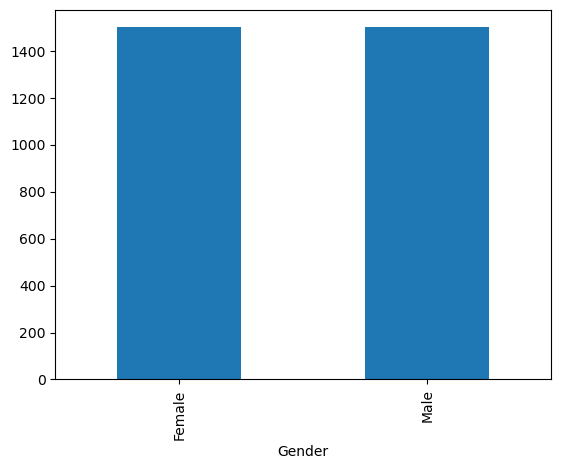

In [80]:
df['Gender'].value_counts().plot(kind='bar')

### Course

<Axes: xlabel='Course'>

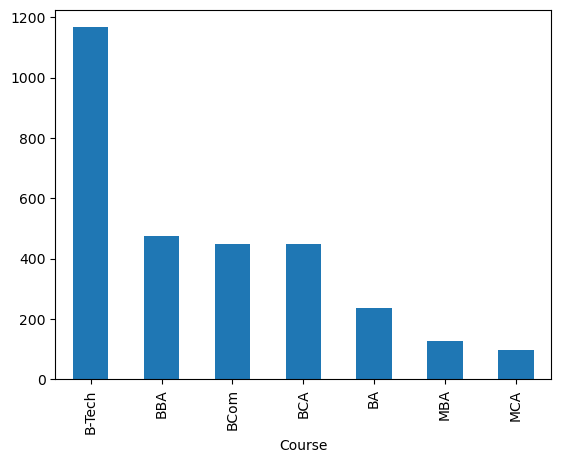

In [122]:
df['Course'].value_counts().plot(kind='bar')

### Grade

<Axes: xlabel='Grade'>

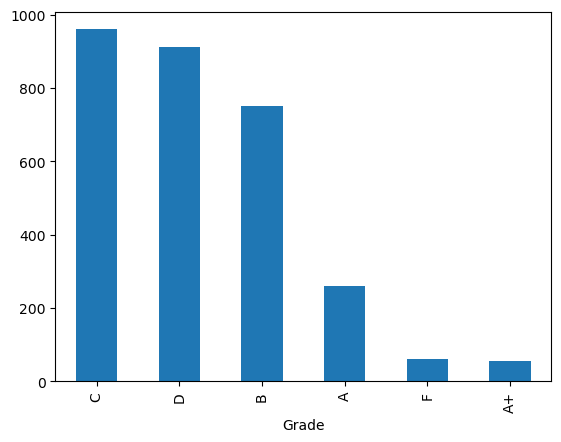

In [131]:
df['Grade'].value_counts().plot(kind='bar')

### Hostel/Day Scholar

In [139]:
df['Hostel/Day Scholar'].value_counts()

Hostel/Day Scholar
Day Scholar    2283
Hostel          717
Name: count, dtype: int64

<Axes: xlabel='Hostel/Day Scholar', ylabel='Count'>

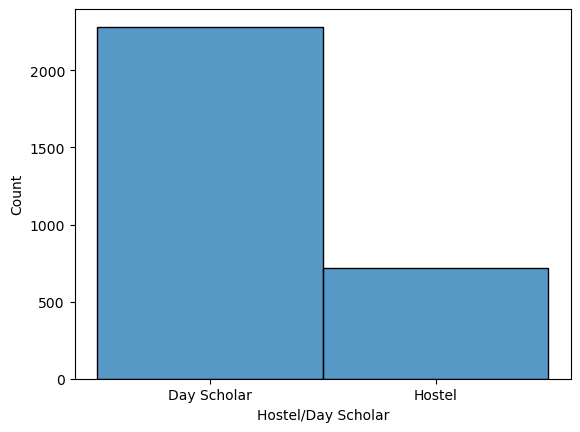

In [141]:
sns.histplot(df['Hostel/Day Scholar'])

<Axes: xlabel='Age', ylabel='count'>

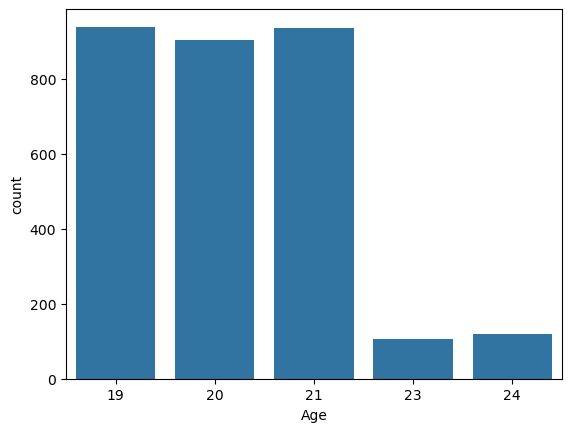

In [151]:
sns.barplot(df['Age'].value_counts())

# Bivariate Analysis

Text(0.5, 1.0, 'Gender wise course Distribution')

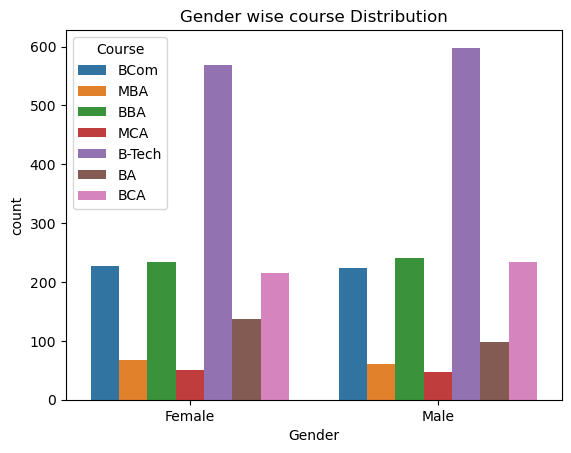

In [260]:
sns.countplot(data=df,x='Gender',hue='Course')
plt.title('Gender wise course Distribution')


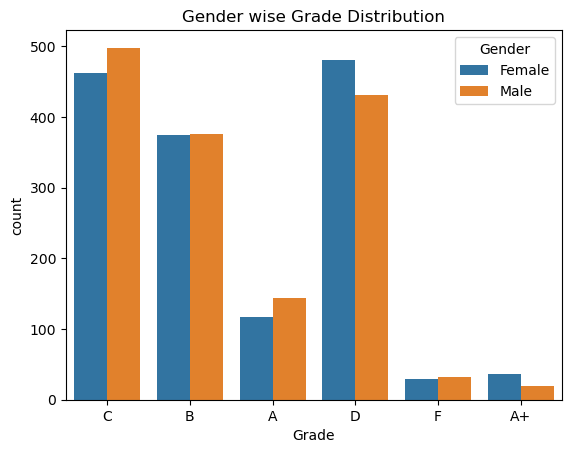

In [258]:
sns.countplot(data=df, x='Grade', hue='Gender')
plot.title('Gender wise Grade Distribution')
plt.show()

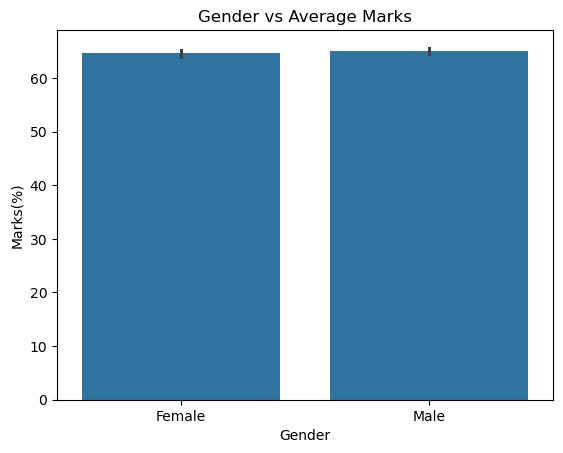

In [236]:
sns.barplot(data=df, x='Gender', y='Marks(%)')
plt.title('Gender vs Average Marks')
plt.show()

Text(0.5, 1.0, 'Course vs enroll of Branch')

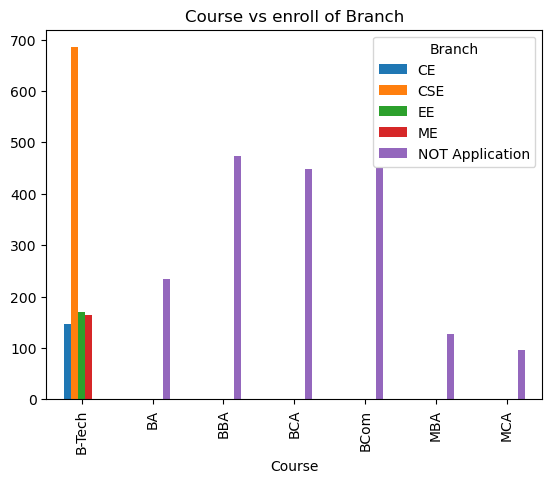

In [261]:
pd.crosstab(df['Course'],df['Branch']).plot(kind='bar')
plt.title('Course vs enroll of Branch')

In [247]:
df

,University-ID,Name,Gender,Course,Branch,Age,Marks(%),Pass/Fail,Grade,Attendance(%),Hostel/Day Scholar
0,2027-0001,Anita Chundawat,Female,BCom,NOT Application,20,65,Pass,C,69,Day Scholar
1,2027-0002,Vijay Mankotia,Male,MBA,NOT Application,23,73,Pass,B,57,Day Scholar
2,2027-0003,Jyoti Aswal,Female,BBA,NOT Application,20,79,Pass,B,78,Day Scholar
3,2027-0004,Chandan Panwar,Male,MCA,NOT Application,23,82,Pass,A,97,Hostel
4,2027-0005,Shashi Hegde,Male,B-Tech,EE,19,77,Pass,B,78,Day Scholar
...,...,...,...,...,...,...,...,...,...,...,...
2995,2027-2996,Gulab Godara,Female,BBA,NOT Application,21,92,Pass,A+,100,Day Scholar
2996,2027-2997,Mast Ram Chauhan,Male,BBA,NOT Application,21,65,Pass,C,32,Day Scholar
2997,2027-2998,Sukhpreet Gill,Female,BBA,NOT Application,19,70,Pass,B,67,Day Scholar
2998,2027-2999,Anjana Bhardwaj,Female,BBA,NOT Application,21,76,Pass,B,62,Hostel


 # Statistics analysis

In [264]:
df['Age'].mean()
# average value

np.float64(20.263666666666666)

In [267]:
df['Age'].median()
# median value in dataset

20.0

In [268]:
df['Age'].min()
# minimine value 

19

In [269]:
df['Age'].max()
#maximum value

24

In [271]:
df['Age'].std()

1.227999409502638

# Conclusion – Student Performance Analysis

In [272]:
The analysis shows that student grades and academic performance can be compared across male and female students.
Grade distribution helps identify the most common grade, 
while gender-wise analysis highlights differences in student performance.
The average marks and box plot provide further insights into marks distribution.
Attendance vs marks analysis helps understand whether attendance is related to academic performance.
Overall, this project helps identify student performance patterns and supports better academic decision-making through data visualization.

SyntaxError: invalid syntax (3037630181.py, line 1)

In [ ]:
# last file save 
# df.to_csv